In [9]:
import pandas as pd

df = pd.read_csv("../data/raw/student-por.csv", sep=";")
print(df.head())
print(df.shape)

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]
(649, 33)


In [10]:
(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [11]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [12]:
df.duplicated()
df.duplicated().sum()
df[df.duplicated()]
df.nunique()

school         2
sex            2
age            8
address        2
famsize        2
Pstatus        2
Medu           5
Fedu           5
Mjob           5
Fjob           5
reason         4
guardian       3
traveltime     4
studytime      4
failures       4
schoolsup      2
famsup         2
paid           2
activities     2
nursery        2
higher         2
internet       2
romantic       2
famrel         5
freetime       5
goout          5
Dalc           5
Walc           5
health         5
absences      24
G1            17
G2            16
G3            17
dtype: int64

In [13]:
numeric_df = df.select_dtypes(include="number")
print(numeric_df.columns)
categorical_df = df.select_dtypes(include=["object", "str"])
print(categorical_df.columns)
print("Numerical columns:", len(numeric_df.columns))
print("Categorical columns:", len(categorical_df.columns))

Index(['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
       'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2',
       'G3'],
      dtype='str')
Index(['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob',
       'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities',
       'nursery', 'higher', 'internet', 'romantic'],
      dtype='str')
Numerical columns: 16
Categorical columns: 17


In [14]:
df["sex"].value_counts()
df["school"].value_counts()
df["address"].value_counts()
df["famsize"].value_counts()
df["sex"].value_counts(normalize=True) * 100
df["Mjob"].value_counts()
df["Mjob"].value_counts(ascending=True)
df["G3"].value_counts().sort_index()

G3
0      15
1       1
5       1
6       3
7      10
8      35
9      35
10     97
11    104
12     72
13     82
14     63
15     49
16     36
17     29
18     15
19      2
Name: count, dtype: int64

In [15]:
# 1. Average grade by gender
df.groupby("sex")["G3"].mean()

# 2. Average grade by school
df.groupby("school")["G3"].mean()

# 3. Average grade by study time
df.groupby("studytime")["G3"].mean()

# 4. Multiple statistical calculations by gender
df.groupby("sex")["G3"].agg(
    ["mean", "median", "min", "max", "count"]
)

# 5. Average grade by school and gender
df.groupby(["school", "sex"])["G3"].mean()

# 6. Average grade by gender and study time
df.groupby(["sex", "studytime"])["G3"].mean()

# 7. Average grade and absences by gender
df.groupby("sex")[["G3", "absences"]].mean()

# 8. Multiple calculations for different columns
df.groupby("sex").agg({
    "G3": ["mean", "max", "min"],
    "absences": ["mean", "sum"],
    "studytime": ["mean", "median"]
})

G3          absences       studytime       
          mean max min      mean   sum      mean median
sex                                                    
F    12.253264  19   0  3.577023  1370  2.073107    2.0
M    11.406015  19   0  3.778195  1005  1.725564    2.0

In [16]:
# 1. Sort students by final grade (ascending)
df.sort_values(by="G3")

# 2. Sort students by final grade (descending)
df.sort_values(by="G3", ascending=False)

# 3. Display the top 10 students by final grade
df.sort_values(by="G3", ascending=False).head(10)

# 4. Display the bottom 10 students by final grade
df.sort_values(by="G3", ascending=True).head(10)

# 5. Sort by multiple columns
df.sort_values(
    by=["G3", "absences"],
    ascending=[False, True]
)

# 6. Find the highest final grade
df["G3"].max()

# 7. Find the lowest final grade
df["G3"].min()

# 8. Find the average final grade
df["G3"].mean()

# 9. Find the median final grade
df["G3"].median()

# 10. Find the top 10 final grades
df["G3"].nlargest(10)

# 11. Find the bottom 10 final grades
df["G3"].nsmallest(10)

163    0
440    0
519    0
563    0
567    0
583    0
586    0
597    0
603    0
605    0
Name: G3, dtype: int64

In [17]:
# 1. Correlation between all numerical columns
df.corr(numeric_only=True)

# 2. Correlation of all features with final grade
df.corr(numeric_only=True)["G3"].sort_values(ascending=False)

# 3. Strongest positive correlations with G3
df.corr(numeric_only=True)["G3"].sort_values(ascending=False).head(10)

# 4. Strongest negative correlations with G3
df.corr(numeric_only=True)["G3"].sort_values().head(10)

# 5. Correlation between study time and final grade
df["studytime"].corr(df["G3"])

# 6. Correlation between absences and final grade
df["absences"].corr(df["G3"])

np.float64(-0.09137905643875617)

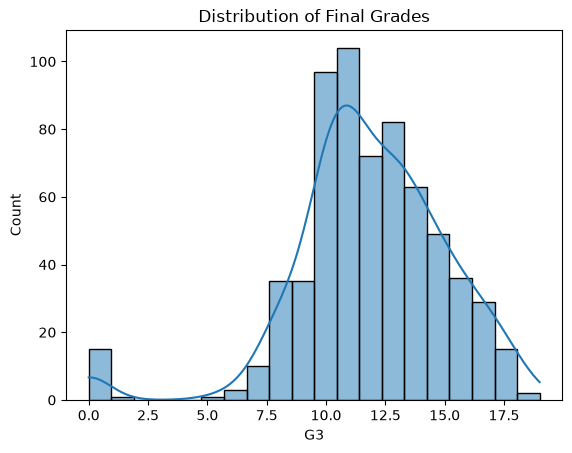

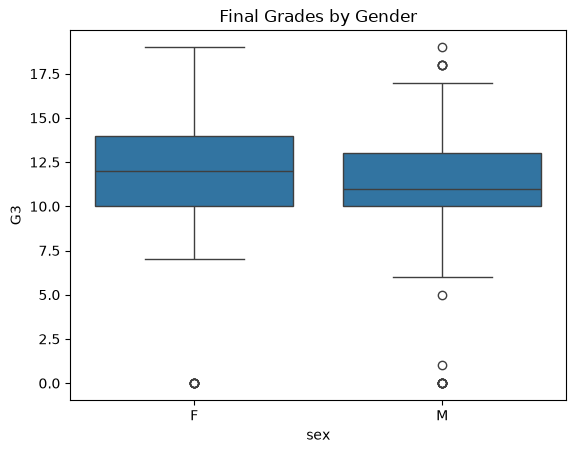

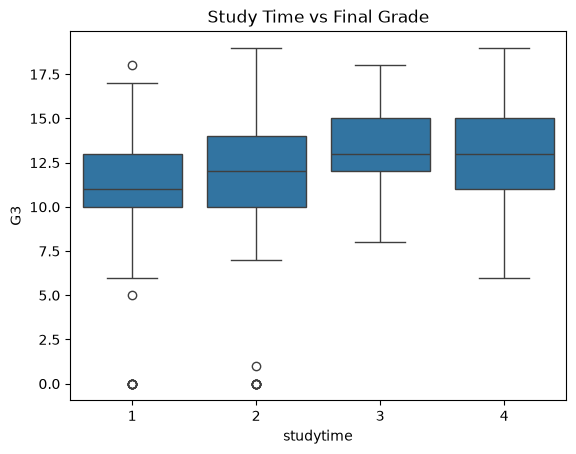

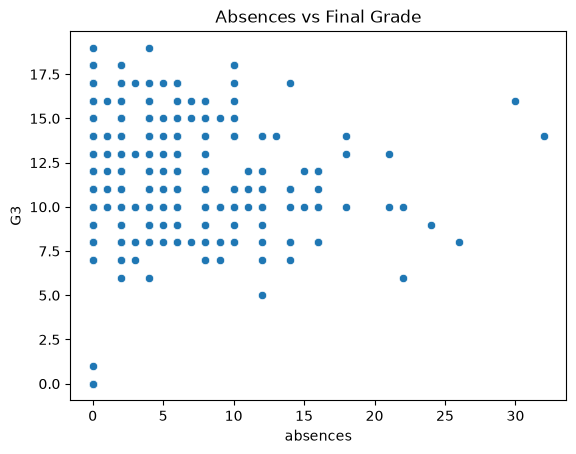

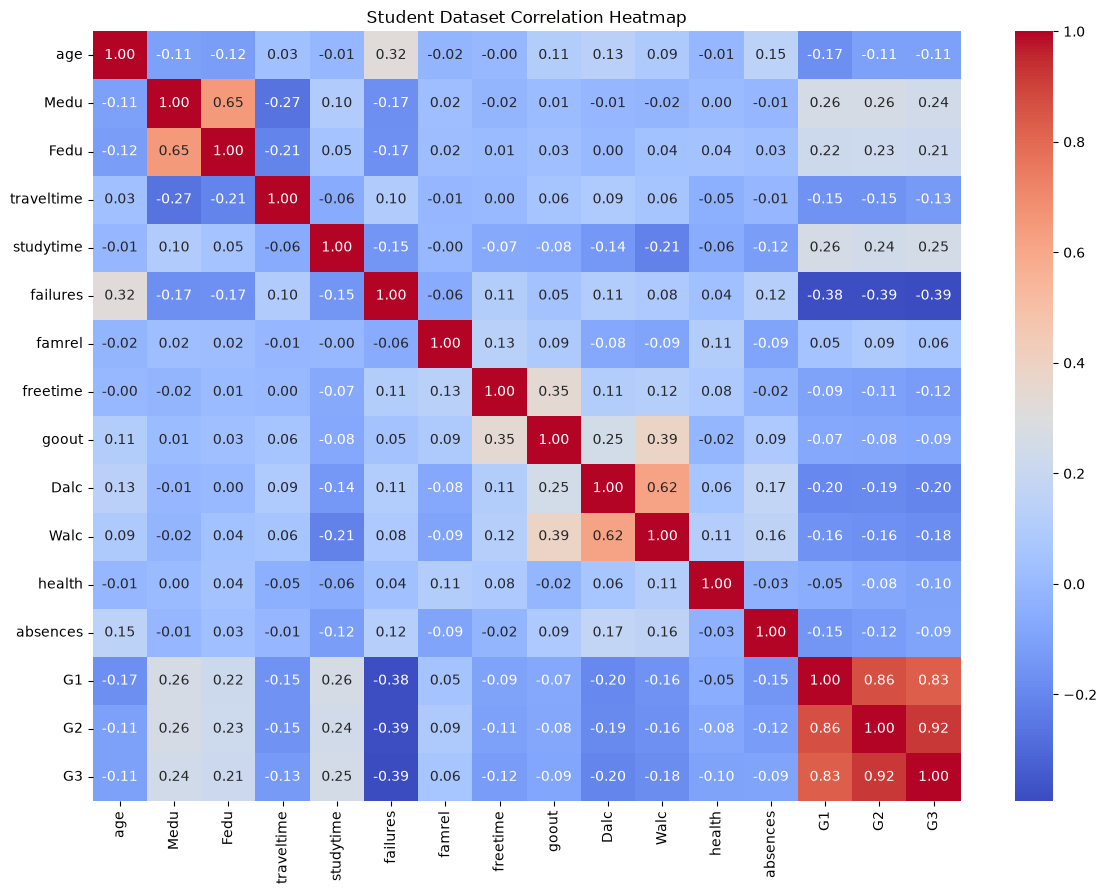

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Final grade distribution
sns.histplot(df["G3"], bins=20, kde=True)
plt.title("Distribution of Final Grades")
plt.show()

# 2. Gender vs final grade
sns.boxplot(data=df, x="sex", y="G3")
plt.title("Final Grades by Gender")
plt.show()

# 3. Study time vs final grade
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Study Time vs Final Grade")
plt.show()

# 4. Absences vs final grade
sns.scatterplot(data=df, x="absences", y="G3")
plt.title("Absences vs Final Grade")
plt.show()

# 5. Correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Student Dataset Correlation Heatmap")
plt.show()

In [19]:
# 1. Create a copy of original dataset
data = df.copy()

# 2. Check missing values
print(data.isnull().sum().sum())

# 3. Check duplicate records
print(data.duplicated().sum())

# 4. Check data types
print(data.dtypes)

# 5. Separate numerical columns
numeric_cols = data.select_dtypes(include="number").columns

# 6. Separate categorical columns
categorical_cols = data.select_dtypes(
    include=["object", "str"]
).columns

# 7. Check unique values in categorical columns
for col in categorical_cols:
    print(col, data[col].unique())

# 8. Check statistical information
print(data.describe())

# 9. Check dataset dimensions
print(data.shape)

0
0
school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object
school <StringArray>
['GP', 'MS']
Length: 2, dtype: str
sex <StringArray>
['F', 'M']
Length: 2, dtype: str
address <StringArray>
['U', 'R']
Length: 2, dtype: str
famsize <StringArray>
['GT3', 'LE3']
Length: 2, dtype: str
Pstatus <StringArray>
['A', 'T']
Length: 2, dtype: str
Mjob <StringArray>
['at_home', 'health', 'othe

In [20]:
# 1. Average of first and second period grades
data["average_grade"] = (data["G1"] + data["G2"]) / 2

# 2. Total previous academic failures
data["has_failed"] = (data["failures"] > 0).astype(int)

# 3. Categorize students based on final grades
data["performance"] = pd.cut(
    data["G3"],
    bins=[-1, 9, 13, 16, 20],
    labels=["Poor", "Average", "Good", "Excellent"]
)

# 4. Display newly created features
data[["G1", "G2", "G3", "average_grade", "has_failed", "performance"]].head()

,G1,G2,G3,average_grade,has_failed,performance
0,0,11,11,5.5,0,Average
1,9,11,11,10.0,0,Average
2,12,13,12,12.5,0,Average
3,14,14,14,14.0,0,Good
4,11,13,13,12.0,0,Average
